# Competing risks: one event count per cause

In a competing-risks problem each subject can fail from one of $K$ causes, and failure from one cause removes
them from risk of the others. A patient who dies cannot later relapse. The standard approach models a
**cause-specific hazard** $\lambda_k(t)$ for each cause: the rate of events of cause $k$ among subjects still
event-free.

Under a piecewise-exponential model the hazards are constant within each cell $c$ (time interval × covariate
pattern). A subject contributes exposure $e_i$ to the cell and at most one event of one cause. The likelihood is

$$\prod_c \prod_k \lambda_{k,c}^{\,d_{k,c}} \exp(-\lambda_{k,c} E_c),$$

so each cell reduces to its total exposure $E_c$ and one event count per cause, $(E_c, d_{1,c}, \dots, d_{K,c})$.
The likelihood is a product of one Poisson term per cause, all sharing the same exposures.

In discrete time, each person-period row has $K+1$ outcomes: no event, or an event of cause $k$. Rows in a cell
share the outcome probabilities, so the cell reduces to its number at risk and event counts, $(r, d_1, \dots, d_K)$,
with a multinomial likelihood.

The notebook first explains the quantity people report, the **cumulative incidence function**, and why it is
needed. It then compares raw-row and cell-summary fits.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import arviz as az
import matplotlib.pyplot as plt

rng = np.random.default_rng(707)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)
TIMINGS = []


def timed_fit(model, label, n_rows, case, kind, **kw):
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    TIMINGS.append({"case": case, "kind": kind, "model": label, "rows": int(n_rows),
                    "wall_s": round(secs, 2), "min_ess_per_s": round(ess / secs, 1)})
    return idata


def save_timings(name):
    Path("timings").mkdir(exist_ok=True)
    Path(f"timings/{name}.json").write_text(json.dumps(TIMINGS, indent=1))
    return pd.DataFrame(TIMINGS).drop(columns="case")

## Simulated data

20,000 subjects followed for 8 periods, with two causes (relapse and death), a treatment flag and three groups
(A, B, C; A is the reference). Treatment lowers the relapse hazard and raises the death hazard. Within a period
the total hazard is $\Lambda = \lambda_1 + \lambda_2$. The time to the first event is exponential with rate
$\Lambda$, and the event is of cause $k$ with probability $\lambda_k / \Lambda$. Subjects are censored at period
boundaries, so the discrete-time model needs no actuarial correction.

In [2]:
n_sub, J, K = 20_000, 8, 2
CAUSES, GROUPS = ["relapse", "death"], ["A", "B", "C"]
treat = rng.integers(0, 2, n_sub)
group = rng.integers(0, 3, n_sub)
base_true = np.log(np.array([
    [0.08, 0.10, 0.11, 0.11, 0.10, 0.09, 0.08, 0.07],     # relapse: rises then falls
    [0.02, 0.02, 0.03, 0.03, 0.04, 0.05, 0.06, 0.07],     # death: rises steadily
]))
bt_true = np.array([-0.5, 0.2])                           # treatment log hazard ratio per cause
bg_true = np.array([[0.0, 0.2, 0.4],
                    [0.0, 0.1, 0.3]])                     # group effects per cause

t_event, cause = np.full(n_sub, np.inf), np.zeros(n_sub, int)
alive = np.ones(n_sub, bool)
for j in range(J):
    lam = np.exp(base_true[:, j][:, None] + bt_true[:, None] * treat + bg_true[np.arange(K)[:, None], group])
    Lam = lam.sum(0)
    w = rng.exponential(1 / Lam)
    hit = alive & (w < 1)
    t_event[hit] = j + w[hit]
    cause[hit] = 1 + (rng.random(hit.sum()) > lam[0, hit] / Lam[hit])
    alive &= ~hit
t_cens = np.minimum(rng.integers(3, 13, n_sub), J).astype(float)
T = np.minimum(t_event, t_cens)
observed_cause = np.where(t_event <= t_cens, cause, 0)

period = np.arange(J)
exposure = np.clip(T[:, None] - period[None, :], 0, 1)
at_risk = (exposure > 0).ravel()
pp = pd.DataFrame({"id": np.repeat(np.arange(n_sub), J)[at_risk],
                   "period": np.tile(period, n_sub)[at_risk],
                   "exposure": exposure.ravel()[at_risk]})
pp["treat"], pp["group"] = treat[pp.id], group[pp.id]
pp["outcome"] = np.where(np.floor(T[pp.id]) == pp.period, observed_cause[pp.id], 0)
print(f"{n_sub:,} subjects -> {len(pp):,} person-period rows")
print(pp.outcome.value_counts().rename(index={0: "none", 1: "relapse", 2: "death"}))

20,000 subjects -> 91,483 person-period rows
outcome
none       79925
relapse     8145
death       3413
Name: count, dtype: int64


In [3]:
cells = (pp.assign(d1=(pp.outcome == 1).astype(int), d2=(pp.outcome == 2).astype(int))
           .groupby(["period", "treat", "group"])
           .agg(E=("exposure", "sum"), r=("outcome", "size"), d1=("d1", "sum"), d2=("d2", "sum"))
           .reset_index())
print(f"{len(pp):,} rows -> {len(cells)} cells")
cells.head()

91,483 rows -> 48 cells


,period,treat,group,E,r,d1,d2
0,0,0,0,3205.342447,3379,285,59
1,0,0,1,3099.194933,3312,342,60
2,0,0,2,3030.609171,3284,390,95
3,0,1,0,3278.031023,3405,193,71
4,0,1,1,3134.322647,3274,181,91


## The models

Both models use the same linear predictor for each cause: a value per period, a treatment effect and group
effects, all cause-specific.

- **Piecewise-exponential.** Raw rows: each row contributes a Poisson term per cause, with mean exposure × hazard
  and an observed 0/1 indicator for that cause. Summaries: one Poisson per cause per cell on $d_k$ with mean
  $E \times \lambda_k$. Coefficients are log hazard ratios.
- **Discrete-time multinomial logit.** Raw rows: each row has outcome probabilities $\text{softmax}(0, \eta_1, \eta_2)$,
  with "no event" as the reference. Summaries: one multinomial per cell on $(r - d_1 - d_2, d_1, d_2)$. Coefficients
  are log-odds relative to "no event". For the raw-row version we add each row's log-probability of its observed
  outcome with `pm.Potential`, which avoids building a full probability array per row.

In [4]:
coords = {"cause": CAUSES, "period": period, "group_eff": GROUPS[1:]}


def eta(df):
    """(K, rows) linear predictor."""
    a = pm.Normal("alpha", -3, 1.5, dims=("cause", "period"))
    b_t = pm.Normal("beta_treat", 0, 1, dims="cause")
    b_g = pm.Normal("beta_group", 0, 1, dims=("cause", "group_eff"))
    g = pt.concatenate([pt.zeros((K, 1)), b_g], axis=1)
    return a[:, df.period.values] + b_t[:, None] * df.treat.values + g[:, df.group.values]


with pm.Model(coords=coords) as pwe_full:
    lam = pm.math.exp(eta(pp))
    for k in range(K):
        pm.Poisson(f"y_{CAUSES[k]}", mu=pp.exposure.values * lam[k], observed=(pp.outcome.values == k + 1).astype(int))

with pm.Model(coords=coords) as pwe_suff:
    lam = pm.math.exp(eta(cells))
    pm.Poisson("d", mu=cells.E.values * lam, observed=cells[["d1", "d2"]].values.T)

with pm.Model(coords=coords) as mnl_full:
    e = eta(pp)
    logits = pt.concatenate([pt.zeros((1, len(pp))), e], axis=0)
    logp = logits - pm.math.logsumexp(logits, axis=0, keepdims=True)
    pm.Potential("loglik", logp[pp.outcome.values, np.arange(len(pp))].sum())

with pm.Model(coords=coords) as mnl_suff:
    e = eta(cells)
    p = pm.math.softmax(pt.concatenate([pt.zeros((1, len(cells))), e], axis=0), axis=0).T
    counts = np.column_stack([cells.r - cells.d1 - cells.d2, cells.d1, cells.d2])
    pm.Multinomial("d", n=cells.r.values, p=p, observed=counts)

fits = {}
for key, name, model, n_rows, case, kind in [
        ("pwe_raw", "piecewise-exp, person-period rows", pwe_full, len(pp), "Competing risks, piecewise exp.", "raw"),
        ("pwe_cells", "piecewise-exp, (E, d_k) per cell", pwe_suff, len(cells), "Competing risks, piecewise exp.", "compressed"),
        ("mnl_raw", "multinomial logit, person-period rows", mnl_full, len(pp), "Competing risks, discrete time", "raw"),
        ("mnl_cells", "multinomial logit, (r, d_k) per cell", mnl_suff, len(cells), "Competing risks, discrete time", "compressed")]:
    fits[key] = timed_fit(model, name, n_rows, case, kind)

NUTS[nutpie]: [alpha, beta_treat, beta_group]
NUTS[nutpie]: [alpha, beta_treat, beta_group]
NUTS[nutpie]: [alpha, beta_treat, beta_group]
NUTS[nutpie]: [alpha, beta_treat, beta_group]


## From hazards to cumulative incidence

The **cumulative incidence function** (CIF) of cause $k$, $F_k(t)$, is the probability of having an event of
cause $k$ by time $t$, with all causes acting. For the piecewise-exponential model, in period $j$ the total hazard
is $\Lambda_j = \sum_k \lambda_{k,j}$. A subject event-free at the start of period $j$ survives it with probability
$e^{-\Lambda_j}$, and has an event of cause $k$ during it with probability $(\lambda_{k,j}/\Lambda_j)(1 - e^{-\Lambda_j})$.
So

$$F_k(j) = \sum_{m \le j} S(m-1)\, \frac{\lambda_{k,m}}{\Lambda_m}\big(1 - e^{-\Lambda_m}\big), \qquad S(m) = \prod_{l \le m} e^{-\Lambda_l}.$$

At every time, event-free survival and the CIFs add to one: $S(t) + \sum_k F_k(t) = 1$.

All curves below are averaged over the three groups in their observed proportions, so they describe the
simulated population rather than one reference group.

In [5]:
gshare = np.bincount(group, minlength=3) / n_sub


def cif_parts(log_lam):
    """log_lam (..., K, J) -> event-free survival S (..., J), CIF (..., K, J), naive 1-KM-style (..., K, J)."""
    lam = np.exp(log_lam)
    Lam = lam.sum(-2, keepdims=True)
    S_prev = np.exp(-np.cumsum(Lam, -1) + Lam)
    cif = np.cumsum(S_prev * lam / Lam * (1 - np.exp(-Lam)), -1)
    naive = 1 - np.exp(-np.cumsum(lam, -1))
    return np.exp(-np.cumsum(Lam, -1))[..., 0, :], cif, naive


def draws_log_lam(idata, tr, g, zero_treat=None):
    post = idata.posterior
    a = post["alpha"].values.reshape(-1, K, J)
    bt = post["beta_treat"].values.reshape(-1, K).copy()
    if zero_treat is not None:
        bt[:, zero_treat] = 0.0
    bg = np.concatenate([np.zeros((a.shape[0], K, 1)), post["beta_group"].values.reshape(-1, K, 2)], -1)
    return a + bt[..., None] * tr + bg[:, :, [g]]


def standardised(idata, tr, zero_treat=None):
    parts = [cif_parts(draws_log_lam(idata, tr, g, zero_treat)) for g in range(3)]
    return [sum(w * p[i] for w, p in zip(gshare, parts)) for i in range(3)]       # S, CIF, naive


def true_standardised(tr, bt=bt_true):
    parts = [cif_parts(base_true + bt[:, None] * tr + bg_true[:, [g]]) for g in range(3)]
    return [sum(w * p[i] for w, p in zip(gshare, parts)) for i in range(3)]


post_pwe = fits["pwe_cells"]
S0, F0, N0 = standardised(post_pwe, 0)
S1, F1, N1 = standardised(post_pwe, 1)
x = period + 1
q = lambda a: np.quantile(a, [0.055, 0.945], 0)

## Why not 1 − Kaplan–Meier per cause?

A common shortcut estimates the incidence of one cause by treating events of the other cause as censored, then
reports $1 - \text{KM}$. Under the model this is $1 - \exp(-\sum_m \lambda_{k,m})$. It answers a different
question: the probability of an event of cause $k$ in a world where the other cause did not exist. In that world
patients who would have relapsed stay at risk of dying, so the naive curve for death is too high. The naive curves
for the two causes also add up to more than the probability of having any event.

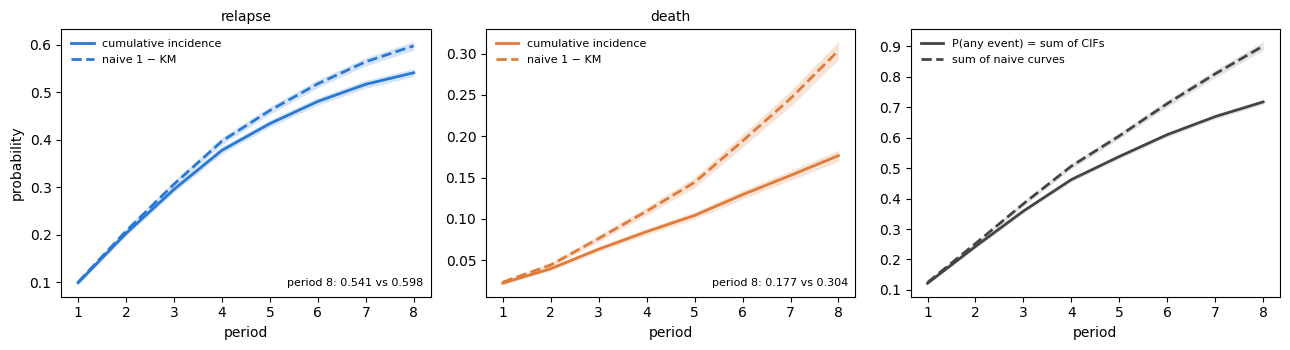

In [6]:
#| label: fig-cr-naive
#| fig-cap: "Control arm, averaged over groups. Left and centre: cumulative incidence (solid, 89% band) and the naive 1 − KM curve that treats the other cause as censoring (dashed, 89% band) for relapse and death. Right: the naive curves summed over causes, against the probability of any event, 1 − S(t), which equals the sum of the cumulative incidences."
cols = {"relapse": "#2a78d6", "death": "#e07b39"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for k, ax in enumerate(axes[:2]):
    col = cols[CAUSES[k]]
    for arr, ls, lab in [(F0[:, k], "-", "cumulative incidence"), (N0[:, k], "--", "naive 1 − KM")]:
        lo, hi = q(arr)
        ax.fill_between(x, lo, hi, color=col, alpha=0.2, lw=0)
        ax.plot(x, arr.mean(0), color=col, ls=ls, lw=2, label=lab)
    ax.set_title(CAUSES[k], fontsize=10)
    ax.set_xlabel("period")
    ax.legend(frameon=False, fontsize=8)
    ax.text(0.98, 0.04, f"period 8: {F0[:, k, -1].mean():.3f} vs {N0[:, k, -1].mean():.3f}", ha="right",
            transform=ax.transAxes, fontsize=8)
axes[0].set_ylabel("probability")
ax = axes[2]
for arr, ls, lab in [(1 - S0, "-", "P(any event) = sum of CIFs"), (N0.sum(1), "--", "sum of naive curves")]:
    lo, hi = q(arr)
    ax.fill_between(x, lo, hi, color="#7a7a7a", alpha=0.2, lw=0)
    ax.plot(x, arr.mean(0), color="#444444", ls=ls, lw=2, label=lab)
ax.set_xlabel("period")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## How the hazards produce the incidence

The left panel shows the cause-specific hazards by arm. Treatment multiplies the relapse hazard by about
$e^{-0.5} \approx 0.61$ and the death hazard by about $e^{0.2} \approx 1.22$, at every time. The stacked panels
show where subjects are at each time: event-free, relapsed first, or died first. The three bands add to one.

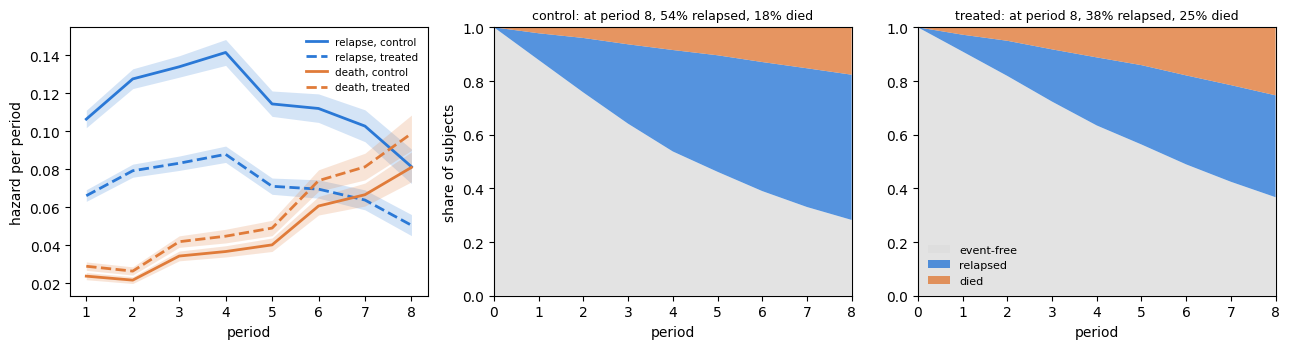

In [7]:
#| label: fig-cr-mechanism
#| fig-cap: "Left: posterior cause-specific hazards per period (averaged over groups, 89% band), control solid and treated dashed. Centre and right: state occupation over time for control and treated subjects (posterior means): event-free, relapsed first, died first."
lam0 = sum(w * np.exp(draws_log_lam(post_pwe, 0, g)) for w, g in zip(gshare, range(3)))
lam1 = sum(w * np.exp(draws_log_lam(post_pwe, 1, g)) for w, g in zip(gshare, range(3)))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
ax = axes[0]
for k in range(K):
    for lam_, ls in [(lam0, "-"), (lam1, "--")]:
        lo, hi = q(lam_[:, k])
        ax.fill_between(x, lo, hi, color=cols[CAUSES[k]], alpha=0.2, lw=0)
        ax.plot(x, lam_[:, k].mean(0), color=cols[CAUSES[k]], ls=ls, lw=2,
                label=f"{CAUSES[k]}, {'treated' if ls == '--' else 'control'}")
ax.set_xlabel("period")
ax.set_ylabel("hazard per period")
ax.legend(frameon=False, fontsize=7.5)
xx = np.concatenate([[0], x])
for ax, (S_, F_), title in [(axes[1], (S0, F0), "control"), (axes[2], (S1, F1), "treated")]:
    layers = [np.concatenate([[1], S_.mean(0)]), np.concatenate([[0], F_[:, 0].mean(0)]), np.concatenate([[0], F_[:, 1].mean(0)])]
    ax.stackplot(xx, *layers, colors=["#dddddd", cols["relapse"], cols["death"]], alpha=0.8,
                 labels=["event-free", "relapsed", "died"])
    ax.set_ylim(0, 1)
    ax.set_xlim(0, J)
    ax.set_title(f"{title}: at period 8, {layers[1][-1]:.0%} relapsed, {layers[2][-1]:.0%} died", fontsize=9)
    ax.set_xlabel("period")
axes[1].set_ylabel("share of subjects")
axes[2].legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

## The treatment effect on the probabilities

The decision-relevant contrast is the difference in cumulative incidence between treated and control subjects,
here averaged over groups. Treatment lowers relapse incidence and raises death incidence.

Treatment raises death incidence by two routes. It raises the death hazard directly, and by preventing relapse it
keeps more subjects at risk of dying. Setting one treatment coefficient to zero at a time, in every posterior draw,
separates the two routes.

In [8]:
F_relapse_only = standardised(post_pwe, 1, zero_treat=1)[1]     # treatment acts on relapse only
F_death_only = standardised(post_pwe, 1, zero_treat=0)[1]       # treatment acts on death only
routes = {"both routes": F1[:, 1, -1] - F0[:, 1, -1],
          "via fewer relapses only": F_relapse_only[:, 1, -1] - F0[:, 1, -1],
          "via higher death hazard only": F_death_only[:, 1, -1] - F0[:, 1, -1]}
tF0 = true_standardised(0)[1][1, -1]
truth = {"both routes": true_standardised(1)[1][1, -1] - tF0,
         "via fewer relapses only": true_standardised(1, np.array([bt_true[0], 0.0]))[1][1, -1] - tF0,
         "via higher death hazard only": true_standardised(1, np.array([0.0, bt_true[1]]))[1][1, -1] - tF0}

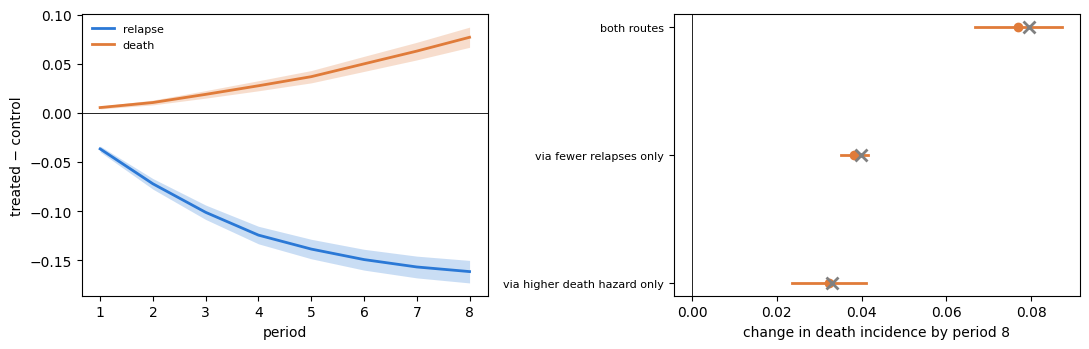

In [9]:
#| label: fig-cr-effect
#| fig-cap: "Left: difference in cumulative incidence, treated minus control, by cause over time (averaged over groups, 89% band). Right: the treatment effect on death incidence by period 8, split into the route through fewer relapses and the route through the higher death hazard (posterior mean and 89% interval); grey crosses are the true values."
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for k in range(K):
    d = F1[:, k] - F0[:, k]
    lo, hi = q(d)
    ax.fill_between(x, lo, hi, color=cols[CAUSES[k]], alpha=0.25, lw=0)
    ax.plot(x, d.mean(0), color=cols[CAUSES[k]], lw=2, label=CAUSES[k])
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("period")
ax.set_ylabel("treated − control")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
for r, (name, d) in enumerate(routes.items()):
    yv = len(routes) - 1 - r
    ax.plot(np.quantile(d, [0.055, 0.945]), [yv, yv], color=cols["death"], lw=2)
    ax.plot(d.mean(), yv, "o", color=cols["death"])
    ax.plot(truth[name], yv, "x", color="grey", ms=8, mew=2)
ax.set_yticks(range(len(routes))[::-1], list(routes), fontsize=8)
ax.axvline(0, color="k", lw=0.6)
ax.set_xlabel("change in death incidence by period 8")
plt.tight_layout()
plt.show()

The two routes contribute about equally, and they add up to slightly less than the total because they interact:
a higher death hazard matters more when more subjects remain free of relapse.

## The two models agree on what matters

The piecewise-exponential and multinomial-logit models have coefficients on different scales (log hazard ratios
against log-odds), so their coefficients should not be compared directly. Their cumulative incidences can be. For
the discrete model, $F_k(j) = \sum_{m \le j} S(m-1)\,p_{k,m}$ with $p$ from the softmax and $S(m) = \prod_{l\le m}(1 - p_{1,l} - p_{2,l})$.

In [10]:
def mnl_standardised(idata, tr):
    post = idata.posterior
    a = post["alpha"].values.reshape(-1, K, J)
    bt = post["beta_treat"].values.reshape(-1, K)
    bg = np.concatenate([np.zeros((a.shape[0], K, 1)), post["beta_group"].values.reshape(-1, K, 2)], -1)
    out = 0
    for w, g in zip(gshare, range(3)):
        e = a + bt[..., None] * tr + bg[:, :, [g]]
        pk = np.exp(e) / (1 + np.exp(e).sum(1, keepdims=True))
        S_prev = np.cumprod(1 - pk.sum(1, keepdims=True), -1) / (1 - pk.sum(1, keepdims=True))
        out = out + w * np.cumsum(S_prev * pk, -1)
    return out

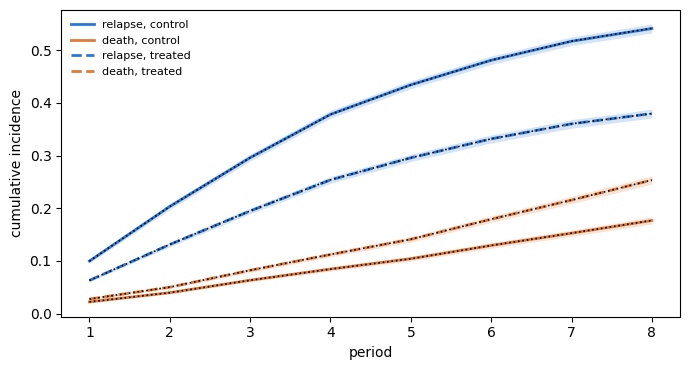

In [11]:
#| label: fig-cr-models
#| fig-cap: "Cumulative incidence by cause and arm from the piecewise-exponential fit (solid, 89% band) and the discrete-time multinomial-logit fit (dotted), both from cell summaries and averaged over groups."
fig, ax = plt.subplots(figsize=(7, 3.8))
for tr, ls, F_ in [(0, "-", F0), (1, "--", F1)]:
    Fm = mnl_standardised(fits["mnl_cells"], tr)
    for k in range(K):
        lo, hi = q(F_[:, k])
        ax.fill_between(x, lo, hi, color=cols[CAUSES[k]], alpha=0.2, lw=0)
        ax.plot(x, F_[:, k].mean(0), color=cols[CAUSES[k]], ls=ls, lw=2,
                label=f"{CAUSES[k]}, {'treated' if tr else 'control'}")
        ax.plot(x, Fm[:, k].mean(0), color="k", ls=":", lw=1.2)
ax.set_xlabel("period")
ax.set_ylabel("cumulative incidence")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## Raw rows vs cell summaries

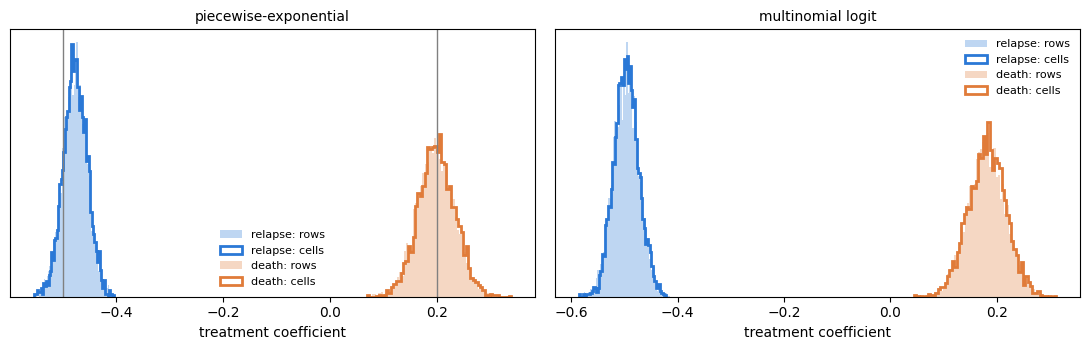

In [12]:
#| label: fig-cr-equiv
#| fig-cap: "Treatment coefficient per cause, raw person-period rows (filled) vs cell summaries (line). Left: piecewise-exponential (log hazard ratio; true values in grey). Right: multinomial logit (log-odds relative to no event)."
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (raw, cel, title) in zip(axes, [("pwe_raw", "pwe_cells", "piecewise-exponential"), ("mnl_raw", "mnl_cells", "multinomial logit")]):
    for k in CAUSES:
        ax.hist(fits[raw].posterior["beta_treat"].sel(cause=k).values.ravel(), bins=60, density=True,
                alpha=0.3, color=cols[k], label=f"{k}: rows")
        ax.hist(fits[cel].posterior["beta_treat"].sel(cause=k).values.ravel(), bins=60, density=True,
                histtype="step", lw=2, color=cols[k], label=f"{k}: cells")
    if raw == "pwe_raw":
        for v in bt_true:
            ax.axvline(v, color="grey", lw=1)
    ax.set_title(title, fontsize=10)
    ax.set_yticks([])
    ax.set_xlabel("treatment coefficient")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [13]:
#| label: tbl-cr-speed
#| tbl-cap: "Person-period rows vs cell summaries for both competing-risks models, with each fit's posterior mean treatment coefficient per cause."
speed = save_timings("07_competing_risks")
for k in CAUSES:
    speed[f"beta_treat {k}"] = [float(fits[key].posterior["beta_treat"].sel(cause=k).mean()) for key in fits]
speed.round(3)

,kind,model,rows,wall_s,min_ess_per_s,beta_treat relapse,beta_treat death
0,raw,"piecewise-exp, person-period rows",91483,40.33,55.1,-0.477,0.198
1,compressed,"piecewise-exp, (E, d_k) per cell",48,2.08,1039.1,-0.477,0.199
2,raw,"multinomial logit, person-period rows",91483,54.12,38.6,-0.497,0.181
3,compressed,"multinomial logit, (r, d_k) per cell",48,3.24,764.7,-0.497,0.181


## What compression gives up

- **Fine–Gray subdistribution hazards.** Fine–Gray models cumulative incidence directly by keeping subjects who failed
  from another cause in the risk set. With censoring, those subjects need inverse-probability-of-censoring weights
  that vary by person and time, so cell counts are no longer sufficient. Cause-specific hazards with a derived
  cumulative incidence, as above, answer the same question and compress cleanly.
- **Shared frailty.** A random effect shared by a subject's rows, linking their risks across causes, makes rows within
  a cell no longer interchangeable.
- **Net risk.** The cause-specific hazards and the cumulative incidences are identified from the data. The naive
  1 − KM curve estimates the risk of one cause with the others removed, and that quantity is identified only if the
  causes act independently. Compression does not change this.
- **Mid-period censoring.** In the discrete-time model, subjects censored part-way through a period would be counted
  as surviving it. The actuarial correction counts them as at risk for half the period. The piecewise-exponential
  model handles this exactly through the exposure.